# Jetsound: Sound detection with Jetson Nano

## Data collection and feature extraction

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import librosa
import math

DATADIR = "sound_database"
DATASET_PATH = "dataset"
CATEGORIES = ['Claps', 'Keyboard', 'Keys']
snippet_length = 3 #seconds     # X resolution of the spectrograms (basically image width) depends on sampling rate
N_MELS = 128                    # Y resolution of the spectrograms (basically image height)

In [5]:
def convert_to_spectrogram(audio_signal, sample_rate, n_mels, fmax=8000):
    # audio_signal
    # sample_rate
    # n_mels : mels bins (Y-resolution of spectrogram)
    # fmax : maximum frequency in spectrogram

    # Returns a 4D tensorflow tensor (1, n_mels, time_steps, 1)
        
    # Create mel spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y = audio_signal,
        sr = sample_rate,
        n_mels = n_mels,
        fmax = fmax
    )
    
    # Convert to decibels
    mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

    # Normalize
    mel_spec = (mel_spec - mel_spec.min()) / (mel_spec.max() - mel_spec.min())

    # Add channel dimension
    mel_spec = mel_spec[..., np.newaxis]  # shape: (n_mels, time_steps, 1)

    # Add batch dimension
    return mel_spec[np.newaxis, ...]

In [6]:
def split_rec_and_create_dataset():
    # 1. Create the main folder if it doesn't exist
    if not os.path.exists(DATASET_PATH):
        os.makedirs(DATASET_PATH)
        print(f"Created folder: {DATASET_PATH}")
    
    count = 0
    
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        
        if not os.path.exists(path):
            print(f"Skipping {category}: Folder not found at {path}")
            continue

        print(f"Processing category: {category}")

        for fname in os.listdir(path):
            if not fname.lower().endswith('.wav'):
                continue
                
            file_path = os.path.join(path, fname)
            
            # Get the clean filename without extension (e.g. "Keys3")
            base_name = os.path.splitext(fname)[0]
            
            try:
                audio, sr = librosa.load(file_path, sr=None)
                
                total_samples = len(audio)
                samples_per_chunk = int(snippet_length * sr)
                parts = math.ceil(total_samples / samples_per_chunk)
                
                for i in range(parts):
                    start = i * samples_per_chunk
                    end = start + samples_per_chunk
                    
                    chunk_audio = audio[start:end]
                    
                    #Zero Padding
                    if len(chunk_audio) < samples_per_chunk:
                        # Calculate how many zeros we need
                        padding_needed = samples_per_chunk - len(chunk_audio)
                        
                        # Pad the array with zeros (silence) at the end
                        # mode='constant' fills with the constant value (default 0)
                        chunk_audio = np.pad(chunk_audio, (0, padding_needed), mode='constant')
                    
                    # Convert to spectrogram (returns 4D tensor)
                    spectro = convert_to_spectrogram(chunk_audio, sr, N_MELS, fmax=8000)
                    
                    # --- SAVING LOGIC ---
                    
                    # 1. Squeeze the dimensions
                    # Your function returns (1, 128, time, 1), but to save as an image
                    # we need a 2D array: (128, time)
                    image_data = spectro.squeeze()
                    
                    # 2. Construct the filename: "Keys3_8.png"
                    # We use i+1 so the first part is "Keys3_1" instead of "Keys3_0"
                    out_name = f"{base_name}_{i+1}.png"
                    out_path = os.path.join(DATASET_PATH, out_name)
                    
                    # 3. Save as image
                    # origin='lower' puts low frequencies at the bottom (standard for audio)
                    # cmap='viridis' or 'magma' gives it the color. Use 'gray' for black/white.
                    plt.imsave(out_path, image_data, origin='lower', cmap='magma')
                    
                    count += 1
                
            except Exception as e:
                print(f"Error processing {fname}: {e}")
                
    print(f"Done! Saved {count} spectrogram images to '{DATASET_PATH}'")

split_rec_and_create_dataset()

Processing category: Claps
Processing category: Keyboard
Processing category: Keys
Done! Saved 450 spectrogram images to 'dataset'


In [7]:
import os
import cv2
import numpy as np
from tensorflow.keras.utils import to_categorical

IMG_HEIGHT = N_MELS  # Must match your saved images
IMG_WIDTH = 259   # Must match your saved images

def load_and_split_data():
    # Initialize empty lists
    x_train, y_train = [], []
    x_test, y_test = [], []

    print("Loading images...")

    for img_name in os.listdir(DATASET_PATH):
        # Skip non-image files
        if not img_name.endswith(".png"):
            continue

        # --- PARSING THE FILENAME ---
        # Example filename: "Keys5_19.png"
        
        # 1. Split "Keys5" from "19.png"
        parts = img_name.split('_') 
        prefix = parts[0] # "Keys5"
        
        # 2. Identify the Category and Recording ID
        category = None
        for cat in CATEGORIES:
            if prefix.startswith(cat):
                category = cat
                break
        
        if category is None:
            print(f"Skipping {img_name}: Could not match category")
            continue
            
        # 3. Extract the recording number (Remove "Keys" from "Keys5" -> "5")
        recording_id = prefix.replace(category, "")
        
        # 4. Get the numerical label (0, 1, or 2)
        label = CATEGORIES.index(category)

        # --- LOAD IMAGE ---
        img_path = os.path.join(DATASET_PATH, img_name)
        
        # Read as GRAYSCALE
        # This ignores the Magma colors and loads strictly based on brightness
        img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        # Safety resize (ensures stacking doesn't crash if one image is off by 1 pixel)
        img_array = cv2.resize(img_array, (IMG_WIDTH, IMG_HEIGHT))
        
        # Normalize pixel values to be between 0 and 1 (Best practice for ML)
        img_array = img_array / 255.0

        # --- SPLIT INTO TRAIN VS TEST ---
        # If the recording ID is '5', it goes to TEST. Everything else goes to TRAIN.
        if recording_id == '5':
            x_test.append(img_array)
            y_test.append(label)
        else:
            x_train.append(img_array)
            y_train.append(label)

    # --- CREATE THE "STACKS" (Convert lists to Numpy Arrays) ---
    x_train = np.array(x_train)
    y_train = np.array(y_train)
    x_test = np.array(x_test)
    y_test = np.array(y_test)
    
    # We need to add a dimension to specify the number of channels (1)
    x_train = x_train[..., np.newaxis]
    x_test = x_test[..., np.newaxis]

    # --- ONE-HOT ENCODING ---
    # Converts label "0" to "[1, 0, 0]"
    y_train = to_categorical(y_train, num_classes=len(CATEGORIES)) 
    y_test = to_categorical(y_test, num_classes=len(CATEGORIES))

    return x_train, y_train, x_test, y_test

# Run the function
x_train, y_train, x_test, y_test = load_and_split_data()

# --- VERIFY THE RESULTS ---
print(f"\n--- Data Loaded ---")
print(f"Training Data Shape (x_train): {x_train.shape}") # Should look like (Num_Samples, Num_Mels, Num_SoundSamples)   (360, 128, 259)
print(f"Training Labels Shape (y_train): {y_train.shape}") #Should look like (Num_Samples, Num_Categories)              (360, 3)
print(f"Test Data Shape (x_test):      {x_test.shape}")
print(f"Test Labels Shape (y_test):      {y_test.shape}")

Loading images...

--- Data Loaded ---
Training Data Shape (x_train): (360, 128, 259, 1)
Training Labels Shape (y_train): (360, 3)
Test Data Shape (x_test):      (90, 128, 259, 1)
Test Labels Shape (y_test):      (90, 3)


## Network architecture

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

model = Sequential([
    Conv2D(64, (3,3), activation='relu', input_shape=(N_MELS, IMG_WIDTH, 1)),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    
    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    
    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(CATEGORIES), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\Pedro\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 257, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 257, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 128, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 126, 64)    │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 126, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 61, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 53760)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,881,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,994,243 (26.68 MB)

 Trainable params: 6,993,731 (26.68 MB)

 Non-trainable params: 512 (2.00 KB)

## Model training

Epoch 1/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.9889 - loss: 0.3539
Epoch 2/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.9972 - loss: 0.0464
Epoch 3/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.9806 - loss: 0.4390


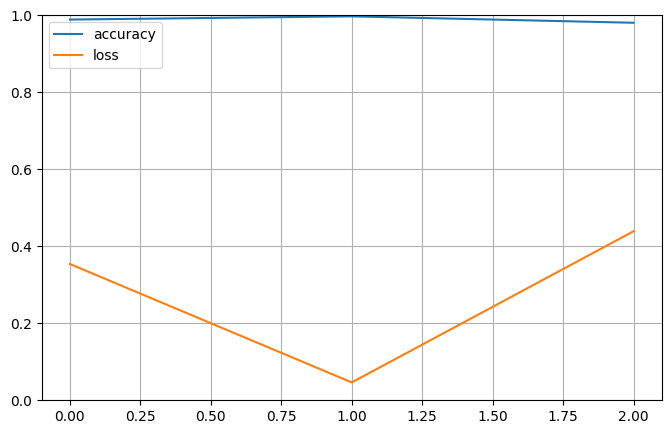

In [10]:
# Train the model
history = model.fit(
    x_train,
    y_train, 
    epochs=3, 
    batch_size=32
)

import pandas as pd
import matplotlib.pyplot as plt

pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 315ms/step

Confusion Matrix:
[[ 0 30  0]
 [ 0 30  0]
 [ 0 30  0]]

Classification Report:
              precision    recall  f1-score   support

       Claps       0.00      0.00      0.00        30
    Keyboard       0.33      1.00      0.50        30
        Keys       0.00      0.00      0.00        30

    accuracy                           0.33        90
   macro avg       0.11      0.33      0.17        90
weighted avg       0.11      0.33      0.17        90



c:\Users\Pedro\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pedro\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pedro\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


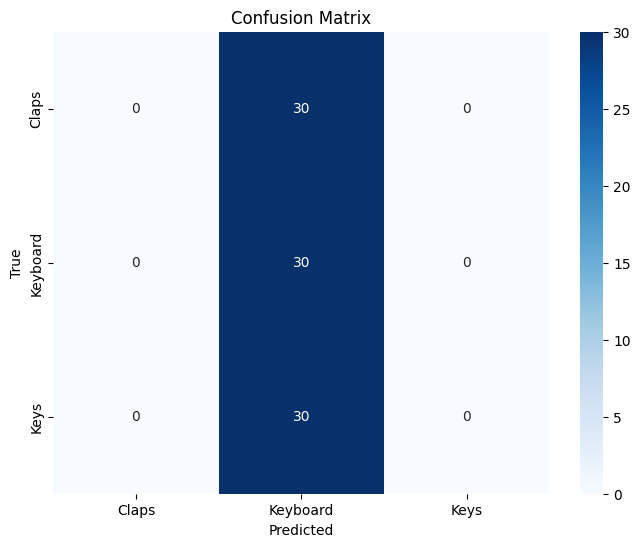

In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get the model's predictions (these will be probabilities)
predictions = model.predict(x_test)

# 2. Convert One-Hot Encoded labels back to Single Integers
# Example: [0, 1, 0] -> 1 (Keyboard)
y_pred_classes = np.argmax(predictions, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# 3. Print the text evaluation
print("\nConfusion Matrix:")
print(confusion_matrix(y_true_classes, y_pred_classes))

print("\nClassification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=CATEGORIES))

# 4. (Optional) Plot a nice heatmap for the Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

## Validation

You need the library "pyaudio" to test this feature.

    pip install pyaudio
    
    conda install conda-forge::pyaudio

In [ ]:
import pyaudio
import wave

# Configuration parameters
FORMAT = pyaudio.paInt16  # 16-bit resolution
CHANNELS = 1              # Mono recording
RATE = 44100              # Sample rate (44.1kHz is standard)
CHUNK = 1024              # Buffer size
RECORD_SECONDS = 5        # Duration of recording
OUTPUT_FILENAME = "test_recording.wav"

audio = pyaudio.PyAudio()

# Start Recording
stream = audio.open(format=FORMAT, channels=CHANNELS,
                    rate=RATE, input=True,
                    frames_per_buffer=CHUNK)

print("Recording...")

frames = []

for i in range(0, int(RATE / CHUNK * RECORD_SECONDS)):
    data = stream.read(CHUNK)
    frames.append(data)

print("Finished recording.")

# Stop and close the stream
stream.stop_stream()
stream.close()
audio.terminate()

# Save the recorded data as a WAV file 
# (THIS NEEDS TO BE CHANGED SO IT IS STORED IN MEMORY TO BE USED IN REAL TIME)
with wave.open(OUTPUT_FILENAME, 'wb') as wf:
    wf.setnchannels(CHANNELS)
    wf.setsampwidth(audio.get_sample_size(FORMAT))
    wf.setframerate(RATE)
    wf.writeframes(b''.join(frames))

print(f"File saved as {OUTPUT_FILENAME}")